# correctionlib: a tutorial with the SIDM corrections

This notebook is the starting point for the `corrections` study. It explains what
correctionlib is, where the CMS correction files live, how to read and evaluate them,
how to write a correction of our own, and how the SIDM framework now uses all of this
through `sidm/tools/corrections.py` and `SidmProcessor(corrections=...)`.

Everything here runs in about a minute with nothing but CVMFS: no EOS, no grid proxy.
The events come from the 200-event 2Mu2E fixture that CI uses,
`tests/data/events_2mu2e_500GeV_200ev.root`.

The notebooks that follow build on this one:

| notebook | question |
|---|---|
| `01_standard_corrections.ipynb` | what each standard correction does to our samples, and whether it is applied correctly |
| `02_applicability.ipynb` | where the standard corrections stop describing our objects |
| `03_impact_on_results.ipynb` | how much the corrections and their uncertainties move the signal-region yields |

In [1]:
import os, re, sys, gzip, subprocess, tempfile, warnings
import numpy as np
import awkward as ak
import hist
import yaml
import matplotlib.pyplot as plt
import mplhep as hep
from matplotlib.colors import LogNorm

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import corrections, utilities
from sidm.studies.corrections import corrections_study as study
# `import correctionlib` works too in the CMSSW_17 kernel, see section 1
correctionlib = corrections.import_correctionlib()
import correctionlib.schemav2 as cs
import correctionlib.convert

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
print("correctionlib", correctionlib.__version__, "from", os.path.dirname(correctionlib.__file__))

# one fixed colour per role, used in every notebook of this study
BLUE, ORANGE, AQUA, GRAY, BLACK = study.BLUE, study.ORANGE, study.AQUA, study.GRAY, study.BLACK

correctionlib 2.9.0 from /uscms_data/d3/scampbel/CMSSW_17_0_0_pre4/src/SIDM/.python_userbase/lib/python3.12/site-packages/correctionlib


## 1. What correctionlib is

A *correction* is any function that turns object or event properties into a number: a
scale factor as a function of $p_T$ and $\eta$, a pileup weight as a function of the
number of interactions, a jet energy correction as a function of $p_T$, $\eta$, the
jet area and $\rho$. For years every POG shipped these in its own format (ROOT
histograms, text files, bespoke C++), and every analysis wrote its own lookup code.

correctionlib replaces that with two things:

* **a JSON schema** in which a correction is a small tree of nodes: `binning` and
  `multibinning` (look up a bin), `category` (switch on a string or integer, used for
  working points and systematic variations), `formula` (a TFormula-style expression),
  `transform` (rewrite an input before the lookup, e.g. $|\eta|$), and `hashprng`
  (a reproducible random number, used for jet smearing);
* **an evaluator** written in C++ with Python bindings, which takes numpy arrays and
  evaluates millions of objects per second.

Every POG publishes its Run 2 UL and Run 3 corrections in this format, and the same file
works in coffea, RDataFrame and plain C++. A file is a `CorrectionSet`: a list of named
corrections, each with declared inputs and one output.

**A note on our environment.** The PyPI wheel of correctionlib cannot be imported
under `cmsenv`: CMSSW puts its own, older `libcorrectionlib.so` on `LD_LIBRARY_PATH`
and the wheel's compiled core binds to it (`undefined symbol: __cxa_call_terminate`).
In the CMSSW_17 kernel this is fixed by building correctionlib from source into
`.python_userbase` with `sidm/scripts/install_correctionlib_cmssw.sh`. The Condor
workers still use the wheel under CMSSW_14, so `sidm/tools/corrections.py` also loads
correctionlib through `corrections.import_correctionlib()`, which binds the core to
the library it ships with. Use that function in code that has to run everywhere.

## 2. Where the CMS files live

The central corrections are published by the CMS analysis-corrections project
(https://cms-analysis-corrections.docs.cern.ch/) and synced to CVMFS:

`/cvmfs/cms-griddata.cern.ch/cat/metadata/<POG>/<campaign>/<date>/<file>.json.gz`

The older `/cvmfs/cms.cern.ch/rsync/cms-nanoAOD/jsonpog-integration` tree still exists
but is deprecated, and its README says so. For 2018 UL NanoAODv9 the campaign is
`Run2-2018-UL-NanoAODv9`. Each campaign directory holds dated snapshots plus a
`latest` copy. We **pin a dated snapshot** in `sidm/configs/corrections.yaml`, so a
result can be reproduced after a POG publishes new numbers, and moving to a new
snapshot is a deliberate, recorded change.

In [2]:
corr = corrections.Corrections("2018")
print("json_root:", corr.json_root)
for pog in ["LUM", "MUO", "EGM", "JME", "BTV"]:
    snapshots = sorted(os.listdir(os.path.join(corr.json_root, pog, "Run2-2018-UL-NanoAODv9")))
    print(f"  {pog}: {len(snapshots)} snapshots, newest {[s for s in snapshots if s != 'latest'][-1]}")

print("\nPinned in configs/corrections.yaml:")
for name, entry in corr.config.items():
    if isinstance(entry, dict):
        for f in corr.files(name):
            print(f"  {name:18s} {f}")

json_root: /cvmfs/cms-griddata.cern.ch/cat/metadata


  LUM: 5 snapshots, newest 2021-09-10
  MUO: 11 snapshots, newest 2024-07-02
  EGM: 7 snapshots, newest 2024-07-02
  JME: 24 snapshots, newest 2026-06-10
  BTV: 23 snapshots, newest 2025-08-19

Pinned in configs/corrections.yaml:
  pileup             LUM/Run2-2018-UL-NanoAODv9/2021-09-10/puWeights.json.gz
  muon_id            MUO/Run2-2018-UL-NanoAODv9/2024-07-02/muon_JPsi.json.gz
  muon_id            MUO/Run2-2018-UL-NanoAODv9/2024-07-02/muon_Z.json.gz
  electron_reco      EGM/Run2-2018-UL-NanoAODv9/2024-07-02/electron.json.gz
  electron_id        EGM/Run2-2018-UL-NanoAODv9/2024-07-02/electron.json.gz
  photon_id          EGM/Run2-2018-UL-NanoAODv9/2024-07-02/photon.json.gz
  photon_pixel_veto  EGM/Run2-2018-UL-NanoAODv9/2024-07-02/photon.json.gz
  jet_energy         JME/JER-Smearing/2026-09-18/jer_smear.json.gz
  jet_energy         JME/Run2-2018-UL-NanoAODv9/2026-06-10/jet_jerc.json.gz
  jet_veto           JME/Run2-2018-UL-NanoAODv9/2026-06-10/jetvetomaps.json.gz
  btag              

## 3. Opening and inspecting a file

`correctionlib.CorrectionSet.from_file` reads plain or gzipped JSON. A `CorrectionSet`
behaves like a dictionary of corrections; each correction knows its inputs and output.

In [3]:
pu_file = corr.path(corr.entry("pileup")["file"])
pu_set = correctionlib.CorrectionSet.from_file(pu_file)
print("corrections in the file:", list(pu_set))
pu = pu_set["Collisions18_UltraLegacy_goldenJSON"]
for var in pu.inputs:
    print(f"  input  {var.name:20s} {var.type:6s} {var.description}")
print(f"  output {pu.output.name:20s} {pu.output.type:6s} {pu.output.description}")

corrections in the file: ['Collisions18_UltraLegacy_goldenJSON']
  input  NumTrueInteractions  real   Number of true interactions
  input  weights              string nominal, up, or down
  output weight               real   Event weight for pileup reweighting


The command-line tool gives the same information with the allowed ranges, and is the
quickest way to look inside a file you have not used before. From a shell:
`correction summary <file>` (or `python3 -m correctionlib.cli summary <file>`).

In [4]:
summary = subprocess.run([sys.executable, "-m", "correctionlib.cli", "summary", pu_file],
                         capture_output=True, text=True, env={**os.environ, "COLUMNS": "100"})
print(re.sub(r"\x1b\[[0-9;]*m", "", summary.stdout))   # drop the terminal colour codes

─ Corrections in file /cvmfs/cms-griddata.cern.ch/cat/metadata/LUM/Run2-2018-UL-NanoAODv9/2021-09… ─
CorrectionSet (schema v2)
No description
📂
└── 📈 Collisions18_UltraLegacy_goldenJSON (v0)
    No description
    Node counts: Category: 1, Binning: 3
    ╭──────────── ▶ input ────────────╮ ╭───────── ▶ input ─────────╮
    │ NumTrueInteractions (real)      │ │ weights (string)          │
    │ Number of true interactions     │ │ nominal, up, or down      │
    │ Range: [0.0, 99.0), overflow ok │ │ Values: down, nominal, up │
    ╰─────────────────────────────────╯ ╰───────────────────────────╯
    ╭───────────── ◀ output ──────────────╮
    │ weight (real)                       │
    │ Event weight for pileup reweighting │
    ╰─────────────────────────────────────╯



## 4. Evaluating

`evaluate` takes one argument per input, in the declared order. Scalars, numpy arrays
and awkward arrays all work, and scalars broadcast against arrays. String inputs
(categories such as `"nominal"`) must be scalars; correctionlib refuses arrays of
strings.

The muon ID scale factor needs $\eta$, $p_T$ and the name of the value to return:

In [5]:
from coffea.nanoevents import NanoEventsFactory
from sidm.tools import sidm_processor, llpnanoaodschema  # the processor import patches a NanoAOD index transform

fixture = os.path.join(sidm_path, "tests", "data", "events_2mu2e_500GeV_200ev.root")
events = NanoEventsFactory.from_root({fixture: "Events"},
                                     schemaclass=llpnanoaodschema.LLPNanoAODSchema).events()

muon_z = correctionlib.CorrectionSet.from_file(corr.path("MUO/Run2-2018-UL-NanoAODv9/2024-07-02/muon_Z.json.gz"))
loose_id = muon_z["NUM_LooseID_DEN_TrackerMuons"]
print("inputs:", [v.name for v in loose_id.inputs])

print("scalar:", loose_id.evaluate(1.1, 45.0, "nominal"))
print("numpy: ", loose_id.evaluate(np.array([0.3, 1.1, 2.2]), np.array([25.0, 45.0, 80.0]), "nominal"))

muons = events.Muon[events.Muon.looseId & (events.Muon.pt > 20) & (abs(events.Muon.eta) < 2.4)]
sf = loose_id.evaluate(muons.eta, muons.pt, "nominal")       # jagged in, jagged out
print("awkward:", sf[:4].tolist())

inputs: ['eta', 'pt', 'scale_factors']
scalar: 0.998412748956228
numpy:  [0.99927255 0.99841275 0.99314051]
awkward: [[0.9986594037107576], [0.9986594037107576], [], [0.9986594037107576]]


## 5. What happens outside the measured range

Every `binning` node declares a `flow`: `"clamp"` uses the nearest bin, `"error"`
raises, and a number is returned as is. The pileup weights clamp: an event with more
interactions than the last bin gets the last weight. The muon SFs raise instead: the
Z-based measurement starts at 15 GeV, and asking for 10 GeV is an error rather than a
silent extrapolation.

In [6]:
print("pileup at 99 and 150 interactions (clamped):", pu.evaluate(np.array([99.0, 150.0]), "nominal"))
try:
    loose_id.evaluate(0.5, 10.0, "nominal")
except Exception as err:
    print("muon SF at 10 GeV:", type(err).__name__, err)

pileup at 99 and 150 interactions (clamped): [1. 1.]
muon SF at 10 GeV: RuntimeError Index below bounds in Binning for input argument 1 value: 10.000000


Our lepton-jet muons start at 5 GeV, so `sidm/tools/corrections.py` stitches two
measurements together: the J/psi-based SFs below 20 GeV and the Z-based ones above.
Each piece in the config carries its $p_T$ range, objects outside every piece get an
SF of 1, and $|\eta|$ is clipped just inside the last bin edge. The resulting SF over
the full $p_T$ range, for the barrel and the endcap:

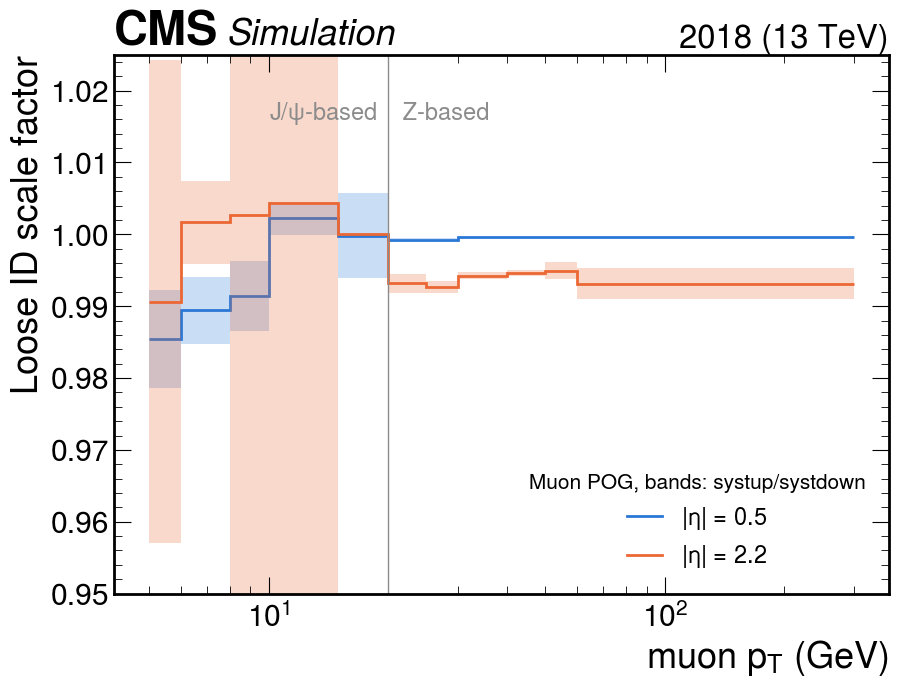

In [7]:
# The SF is binned, so draw it as a hist.Hist on the measurement's own pT bins:
# J/psi-based bins below 20 GeV, Z-based bins above
edges = [5, 6, 8, 10, 15, 20, 25, 30, 40, 50, 60, 120, 300]
centers = 0.5 * (np.array(edges[1:]) + np.array(edges[:-1]))
fig, ax = plt.subplots(figsize=(10, 7))
for eta, color, label in [(0.5, BLUE, r"$|\eta|$ = 0.5"), (2.2, ORANGE, r"$|\eta|$ = 2.2")]:
    toy = ak.Array([[{"pt": p, "eta": eta} for p in centers]])
    sf = {}
    for which in ("nominal", "up", "down"):
        sf[which] = hist.Hist(hist.axis.Variable(edges, name="pt", label=r"muon $p_T$ (GeV)"))
        sf[which].view()[:] = ak.to_numpy(ak.flatten(corr.object_sf("muon_id", toy, "looseID", which)))
    hep.histplot(sf["nominal"], ax=ax, color=color, lw=2, label=label, yerr=False, flow="none", edges=False)
    study.band(ax, sf["up"], sf["down"], color)
ax.axvline(20, color=GRAY, lw=1)
ax.text(19, 1.016, r"J/$\psi$-based ", color=GRAY, fontsize=17, ha="right")
ax.text(21, 1.016, " Z-based", color=GRAY, fontsize=17, ha="left")
ax.set_xscale("log")
ax.set_ylabel("Loose ID scale factor")
ax.set_ylim(0.95, 1.025)
ax.legend(loc="lower right", fontsize=17, title="Muon POG, bands: systup/systdown", title_fontsize=15)
study.cms_label(ax)
study.save(fig, "tutorial_muon_sf_vs_pt")
plt.show()

## 6. Categories and systematic variations

Variations are selected with a string input, and every POG names them differently.
This is the most common source of silent mistakes, so the names are written into the
config once (`variations:`) and never typed in analysis code:

| POG | input | nominal | up | down |
|---|---|---|---|---|
| LUM (pileup) | `weights` | `nominal` | `up` | `down` |
| MUO | `scale_factors` | `nominal` | `systup` | `systdown` |
| EGM | `ValType` | `sf` | `sfup` | `sfdown` |
| BTV | `systematic` | `central` | `up` | `down` |

The photon pixel-veto SF has no $p_T$ or $\eta$ input at all, only categories: the
year, the variation, the ID working point, and a detector-region label. Because string
inputs must be scalars, the framework evaluates it once per region.

In [8]:
photon_set = correctionlib.CorrectionSet.from_file(corr.path("EGM/Run2-2018-UL-NanoAODv9/2024-07-02/photon.json.gz"))
pixveto = photon_set["UL-Photon-PixVeto-SF"]
print("inputs:", [(v.name, v.type) for v in pixveto.inputs])
for region in ["EBInc", "EEInc"]:
    print(f"  {region}:", {key: round(pixveto.evaluate("2018", key, "Loose", region), 4)
                          for key in ("sf", "sfup", "sfdown")})
try:
    pixveto.evaluate("2018", "sf", "Loose", np.array(["EBInc", "EEInc"]))
except ValueError as err:
    print("array of strings:", err)

inputs: [('year', 'string'), ('ValType', 'string'), ('WorkingPoint', 'string'), ('HasPixBin', 'string')]
  EBInc: {'sf': 0.9623, 'sfup': 0.9639, 'sfdown': 0.9607}
  EEInc: {'sf': 0.8833, 'sfup': 0.891, 'sfdown': 0.8756}
array of strings: Array arguments only allowed for integer and real input types


## 7. Compound corrections: re-deriving the jet energy correction

A compound correction chains several corrections, each fed the output of the previous
one. The JEC `L1L2L3Res` compound applies the pileup offset (L1FastJet), then the
relative and absolute response (L2, L3). It needs the **raw** jet $p_T$, which NanoAOD
stores as `pt * (1 - rawFactor)`.

NanoAODv9 jets are already corrected, with `Summer19UL18_V5`, the current tag. We do
not apply the JEC again, but recomputing it is how we *check* that: if the tag were
stale, the ratio below would be shifted and spread by percents.

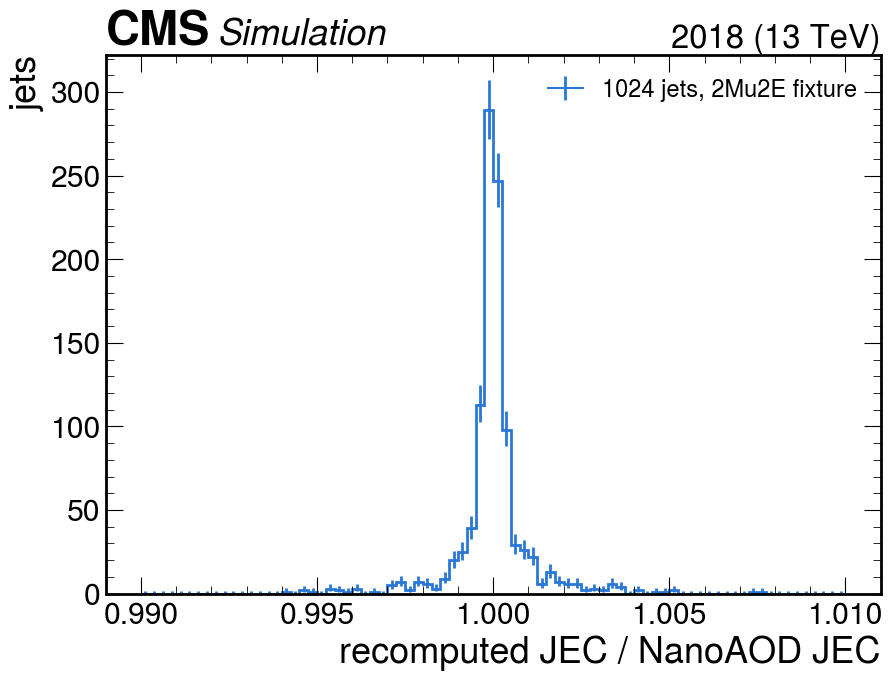

median 0.99998, 99% within 0.0046


In [9]:
jets = events.Jet
jec_recomputed = corr.jec_factor(jets, events.fixedGridRhoFastjetAll)
jec_nanoaod = 1 / (1 - jets.rawFactor)
ratio = ak.to_numpy(ak.flatten(jec_recomputed / jec_nanoaod))

h_ratio = study.h1(ratio, hist.axis.Regular(80, 0.99, 1.01, name="ratio", label="recomputed JEC / NanoAOD JEC"))
fig, ax = plt.subplots(figsize=(10, 7))
hep.histplot(h_ratio, ax=ax, color=BLUE, lw=2, label=f"{len(ratio)} jets, 2Mu2E fixture", flow="sum")
ax.set_ylabel("jets")
ax.legend(fontsize=17)
study.cms_label(ax)
study.save(fig, "tutorial_jec_closure")
plt.show()
print(f"median {np.median(ratio):.5f}, 99% within {np.quantile(abs(ratio - 1), 0.99):.4f}")

The residual spread is NanoAOD's lossy float storage, not a physics difference:
`Jet_rawFactor` keeps 6 mantissa bits and `Jet_pt` keeps 10, so the raw $p_T$ we
rebuild is off by a few per mille, and the JEC evaluated at it differs by that much.

The same factor is large for some jets. A jet with `rawFactor = -0.5` has been
corrected *down* by a third. That matters for us because the lepton-jet isolation is
computed from the corrected energy of the jet matched to each lepton jet; notebook 02
follows this up.

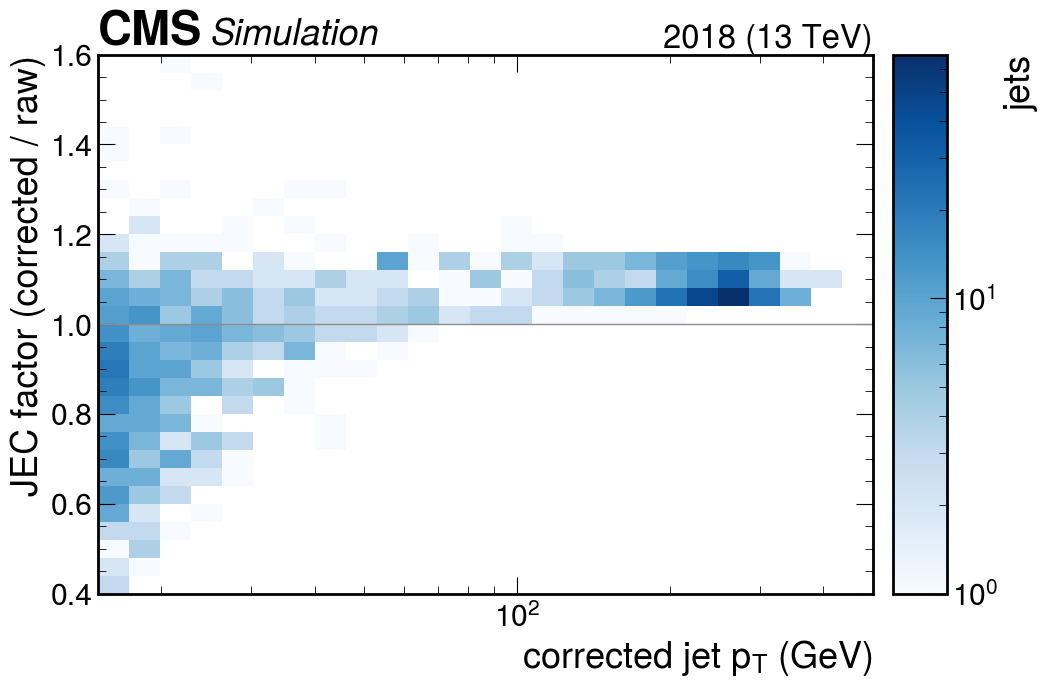

In [10]:
jec_all = ak.to_numpy(ak.flatten(jec_nanoaod))
pt_all = ak.to_numpy(ak.flatten(jets.pt))
h_jec = hist.Hist(
    hist.axis.Regular(25, 15, 500, transform=hist.axis.transform.log, name="pt", label=r"corrected jet $p_T$ (GeV)"),
    hist.axis.Regular(30, 0.4, 1.6, name="jec", label="JEC factor (corrected / raw)"),
)
h_jec.fill(pt=pt_all, jec=jec_all)
fig, ax = plt.subplots(figsize=(10, 7))
art = hep.hist2dplot(h_jec, ax=ax, norm=LogNorm(vmin=1), cmap="Blues", flow="none")
art.cbar.set_label("jets")
ax.set_xscale("log")
ax.axhline(1, color=GRAY, lw=1)
study.cms_label(ax)
study.save(fig, "tutorial_jec_vs_pt")
plt.show()

## 8. Reproducible random numbers: JER smearing

Simulated jets are smeared to match the jet energy resolution in data. Jets matched to
a generator jet are scaled towards it; the others are smeared with a Gaussian random
number. The `JERSmear` correction draws that number with a `hashprng` node seeded from
the jet and event properties, so the same jet always gets the same smearing and a job
rerun gives an identical output.

identical on a second call: True


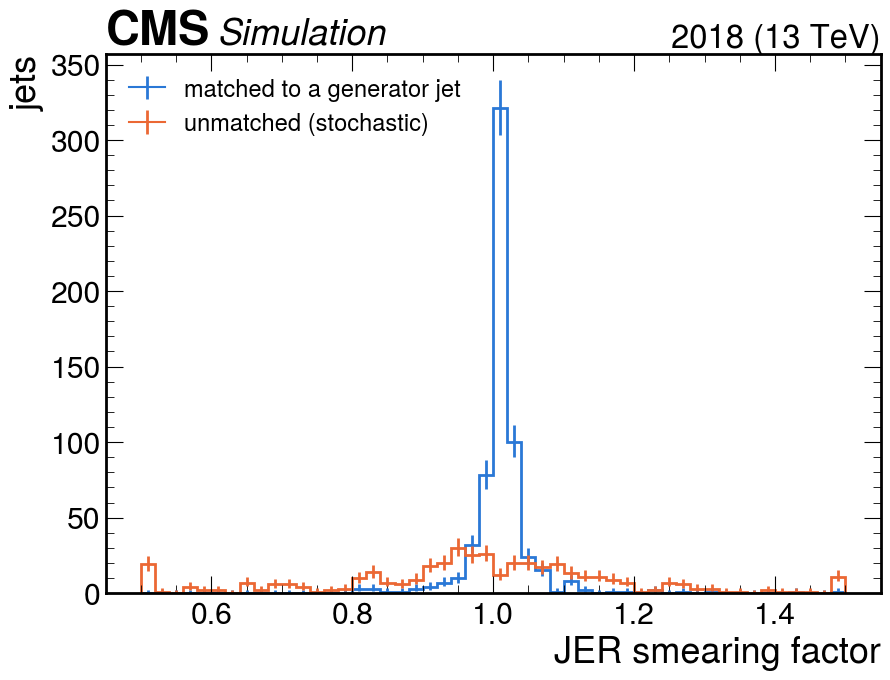

In [11]:
rho, event_id = events.fixedGridRhoFastjetAll, events.event
smear = corr.jer_smearing_factor(jets, rho, event_id)
again = corr.jer_smearing_factor(jets, rho, event_id)
print("identical on a second call:", bool(ak.all(ak.flatten(smear == again))))

matched = ak.to_numpy(ak.flatten(~ak.is_none(jets.matched_gen, axis=-1)))
factor = ak.to_numpy(ak.flatten(smear))
axis = hist.axis.Regular(50, 0.5, 1.5, name="smear", label="JER smearing factor")
fig, ax = plt.subplots(figsize=(10, 7))
hep.histplot([study.h1(factor[matched], axis), study.h1(factor[~matched], axis)], ax=ax, color=[BLUE, ORANGE],
             lw=2, label=["matched to a generator jet", "unmatched (stochastic)"], flow="sum")
ax.set_ylabel("jets")
ax.legend(loc="upper left", fontsize=17)
study.cms_label(ax)
study.save(fig, "tutorial_jer_smearing")
plt.show()

## 9. Writing a correction of our own

The standard corrections do not cover everything we select (notebook 02 lists what is
missing: DSA muons, the displaced-muon triggers, our electron and photon IDs). When we
measure one of those ourselves, the result should go into a correctionlib file too, so
it is evaluated, varied and recorded exactly like the POG numbers.

### 9a. From scratch, with the schema classes

A toy DSA-muon ID scale factor in bins of $p_T$, with up and down variations.
**The numbers are made up** to show the structure.

In [12]:
edges = [10.0, 30.0, 60.0, "inf"]
nominal = [0.96, 0.98, 0.99]

toy_dsa = cs.Correction(
    name="TOY_DSA_ID",
    version=1,
    description="Toy DSA muon ID scale factor (made-up numbers)",
    inputs=[cs.Variable(name="pt", type="real", description="DSA muon pT (GeV)"),
            cs.Variable(name="scale_factors", type="string", description="nominal, systup or systdown")],
    output=cs.Variable(name="weight", type="real"),
    data=cs.Category(nodetype="category", input="scale_factors", content=[
        cs.CategoryItem(key=key, value=cs.Binning(nodetype="binning", input="pt", edges=edges,
                                                  content=[v + shift for v in nominal], flow="clamp"))
        for key, shift in [("nominal", 0.0), ("systup", 0.02), ("systdown", -0.02)]
    ]),
)
print(toy_dsa.to_evaluator().evaluate(np.array([15.0, 45.0, 500.0]), "nominal"))

[0.96 0.98 0.99]


### 9b. From a histogram

Measurements usually end up in a histogram. `correctionlib.convert.from_histogram`
turns a `hist.Hist` into a correction: the axes become the inputs and the bin values
the output. Here a toy trigger scale factor binned in leading-muon $p_T$. The flow is
set to clamp, the whole set is written as `.json.gz`, validated with the command-line
tool and read back.

In [13]:
sf_hist = hist.Hist(hist.axis.Variable([26, 40, 60, 100, 1000], name="pt", label="leading muon pT (GeV)"),
                    name="TOY_TRIGGER_SF", label="weight")
sf_hist[...] = [0.93, 0.96, 0.98, 0.99]           # made-up numbers
toy_trigger = correctionlib.convert.from_histogram(sf_hist)
toy_trigger.data.flow = "clamp"
toy_trigger.description = "Toy trigger scale factor (made-up numbers)"

toy_set = cs.CorrectionSet(schema_version=2, description="SIDM toy corrections",
                           corrections=[toy_dsa, toy_trigger])
tmpdir = tempfile.mkdtemp()
toy_file = os.path.join(tmpdir, "sidm_toy.json.gz")
with gzip.open(toy_file, "wt") as f:
    f.write(toy_set.model_dump_json(exclude_unset=True))

check = subprocess.run([sys.executable, "-m", "correctionlib.cli", "validate", toy_file],
                       capture_output=True, text=True, env={**os.environ, "NO_COLOR": "1"})
print("validate:", check.stdout.strip().splitlines()[-1])
reloaded = correctionlib.CorrectionSet.from_file(toy_file)
print("read back:", list(reloaded), reloaded["TOY_TRIGGER_SF"].evaluate(np.array([30.0, 70.0, 5000.0])))

validate: All OK ✔
read back: ['TOY_DSA_ID', 'TOY_TRIGGER_SF'] [0.93 0.98 0.99]


### 9c. Plugging it into the framework

A correction becomes part of the analysis through an entry in
`sidm/configs/corrections.yaml`. For a file of our own, the path starts with `sidm/`
and resolves inside the repository (the convention would be
`sidm/data/corrections/`). An object correction names the lepton-jet constituent
collection it applies to, and the selection cut whose efficiency it corrects: the
processor applies it only in channels that apply that cut.

Here the toy DSA SF is attached to the `displaced ID` cut on `dsaMuons`, in a
throw-away copy of the config so the real one is untouched:

In [14]:
cfg = yaml.safe_load(open(os.path.join(sidm_path, "sidm", "configs", "corrections.yaml")))
cfg["2018"]["toy_dsa_id"] = {
    "kind": "object",
    "collection": "dsaMuons",           # lepton-jet constituents the SF is evaluated for
    "cut_object": "dsaMuons",           # selections.yaml object whose cuts are checked
    "working_points": {"displaced ID": [{"file": toy_file, "correction": "TOY_DSA_ID"}]},
    "variations": {"nominal": "nominal", "up": "systup", "down": "systdown"},
    "validity": "approximate",
}
toy_cfg = os.path.join(tmpdir, "corrections.yaml")
with open(toy_cfg, "w") as f:
    yaml.safe_dump(cfg, f)

toy_corr = corrections.Corrections("2018", ["pileup", "toy_dsa_id"], cfg=toy_cfg)
print(toy_corr.coverage({"dsaMuons": ["pT > 10 GeV", "displaced ID"]}))
print(toy_corr.coverage({"dsaMuons": ["pT > 10 GeV"]}))

{'toy_dsa_id': 'displaced ID'}
{'toy_dsa_id': None}


## 10. How the SIDM framework uses correctionlib

`sidm/tools/corrections.py` has three layers:

* `Corrections(year, names)` reads `configs/corrections.yaml`, loads each JSON once per
  process, and evaluates the corrections for NanoEvents or lepton-jet constituents.
* `EventWeights` holds the event weight as a product of named factors, each with an up
  and a down value. Unlike coffea's `Weights` it recomputes each variation as a
  product, so a zero factor cannot turn a variation into NaN.
* `SidmProcessor(..., corrections=True)` uses both. For simulation it builds
  genWeight × pileup × prefiring for every event, then, per channel, multiplies in the
  object SFs of that channel's lepton-jet constituents. Data is never corrected.

`corrections=True` means the `default` list of the config: pileup, L1 prefiring, the
muon ID SF and the electron reconstruction SF. Anything else is requested by name.
`monitor_corrections` evaluates corrections without applying them, to see what they
would do; notebook 02 explains why the photon pixel-veto SF is monitored rather than
applied.

Nothing changes when `corrections` is left at its default `None`. With corrections:

1. the weighted column of every cutflow is corrected, and each row also carries the
   weighted count of every **weight category** (`cutflow.variation_yields()`):

   | category | weight |
   |---|---|
   | `nominal` | genWeight × every applied correction |
   | `uncorrected` | genWeight only |
   | `only_<name>` | genWeight × one correction, to see what it does alone |
   | `<name>Up`, `<name>Down` | nominal with one correction shifted |
   | `with_<name>`, `with_<name>Up`, `with_<name>Down` | nominal × a monitored correction (and its shifts) |

2. with `syst_hists=True` every histogram gets a `syst` axis with the same categories;
3. the metadata records which corrections ran and were monitored, which object SFs
   each channel used, and `scaled_sum_weights_corrected`, the sum of genWeight × each
   event correction before any selection;
4. histogram fill functions can read the factors themselves: `objs["weight_factors"]`
   has one column per factor and shift (e.g. `pileup`, `pileupUp`) for the selected
   events, and `objs["object_corrections"]` the working point of each object SF. The
   `corrections_study` collection of `configs/hist_collections.yaml` is built on them.

The normalisation to luminosity × cross section is still computed from the plain
genWeight sum. A correction that changes the total number of events, as pileup
reweighting does slightly, therefore shows up in the yields, as it should.

One run on the fixture, with the default corrections, the pixel veto monitored, and
the `syst` axis:

In [15]:
from coffea import processor

SAMPLE = "2Mu2E_500GeV_1p2GeV_1p9mm"
fileset = {SAMPLE: {"files": [fixture], "metadata": {"is_data": False, "year": "2018", "skim_factor": 1.0}}}
runner = processor.Runner(executor=processor.IterativeExecutor(status=False),
                          schema=llpnanoaodschema.LLPNanoAODSchema, chunksize=100)
channels = ["base", "2mu2e"]
p = sidm_processor.SidmProcessor(channels, ["lj_base", "corrections_weights"], corrections=True,
                                 syst_hists=True, monitor_corrections=["photon_pixel_veto"])
# study.quiet() hides the progress bar and the processor's warnings about
# collections this fixture lacks
with study.quiet():
    out = runner.run(fileset, treename="Events", processor_instance=p)["out"][SAMPLE]

print("applied:", sorted(out["metadata"]["corrections"]), "| monitored:", sorted(out["metadata"]["monitored_corrections"]))
print("object SFs per channel:", {ch: sorted(v) for ch, v in out["metadata"]["object_corrections"].items()})
print("sum of weights, plain genWeight:", float(out["metadata"]["scaled_sum_weights"]))
print("with each event correction:", {k: round(v, 3) for k, v in out["metadata"]["scaled_sum_weights_corrected"].items()})

#--------------------------------------------------------------------------
#                         FastJet release 3.4.3
#                 M. Cacciari, G.P. Salam and G. Soyez                  
#     A software package for jet finding and analysis at colliders      
#                           http://fastjet.fr                           
#	                                                                      
# Please cite EPJC72(2012)1896 [arXiv:1111.6097] if you use this package
# for scientific work and optionally PLB641(2006)57 [hep-ph/0512210].   
#                                                                       
# FastJet is provided without warranty under the GNU GPL v2 or higher.  
# It uses T. Chan's closest pair algorithm, S. Fortune's Voronoi code,
# CGAL and 3rd party plugin jet algorithms. See COPYING file for details.
#--------------------------------------------------------------------------


applied: ['electron_reco', 'l1_prefiring', 'muon_id', 'pileup'] | monitored: ['photon_pixel_veto']
object SFs per channel: {'base': ['electron_reco:always', 'muon_id:looseID', 'photon_pixel_veto:pixelSeed'], '2mu2e': ['electron_reco:always', 'muon_id:looseID', 'photon_pixel_veto:pixelSeed']}
sum of weights, plain genWeight: 200.0
with each event correction: {'pileup': 199.739, 'l1_prefiring': 199.284, 'all_event_level': 199.02}


The cutflow of the `2mu2e` channel, uncorrected and corrected, and the relative change
of every category after the last cut. Raw counts are untouched; only the weights move.

In [16]:
cf = out["cutflow"]["2mu2e"]
print(f"{'cut':36s} {'raw':>5s} {'uncorrected':>12s} {'corrected':>10s}")
for cut, row in cf.rows.items():
    print(f"{cut:36s} {row['raw']:5d} {row['variations']['uncorrected']:12.4f} {row['weighted']:10.4f}")

yields = cf.variation_yields()
print("\nrelative to nominal after the last cut:")
for name, value in yields.items():
    if name != "nominal":
        print(f"  {name:28s} {100 * (value / yields['nominal'] - 1):+6.2f}%")

cut                                    raw  uncorrected  corrected
None                                   200      59.8300    59.3998
pass triggers                           89      26.6244    26.3996
PV filter                               89      26.6244    26.3996
>=2 muons (pf or dsa) pT > 26 GeV       62      18.5473    18.4772
all cosAlpha(mu, mu) > -0.99            62      18.5473    18.4772
>=2 LJs                                 47      14.0601    13.8724
2mu2e                                   47      14.0601    13.8724

relative to nominal after the last cut:
  uncorrected                   +1.35%
  only_pileup                   +0.79%
  only_l1_prefiring             +0.82%
  only_muon_id                  +1.23%
  only_electron_reco            +1.22%
  pileupUp                      -0.67%
  pileupDown                    +1.12%
  l1_prefiringUp                -0.12%
  l1_prefiringDown              +0.12%
  muon_idUp                     +0.02%
  muon_idDown                   -

With `syst_hists=True`, any histogram can be drawn with its variations. The fixture has
only 200 events, so the point is the mechanics: select a channel and a `syst` category
like any other axis.

syst categories: ['nominal', 'uncorrected', 'only_pileup', 'only_l1_prefiring', 'only_muon_id', 'only_electron_reco', 'pileupUp', 'pileupDown', 'l1_prefiringUp', 'l1_prefiringDown', 'muon_idUp', 'muon_idDown', 'electron_recoUp', 'electron_recoDown', 'with_photon_pixel_veto', 'with_photon_pixel_vetoUp', 'with_photon_pixel_vetoDown']


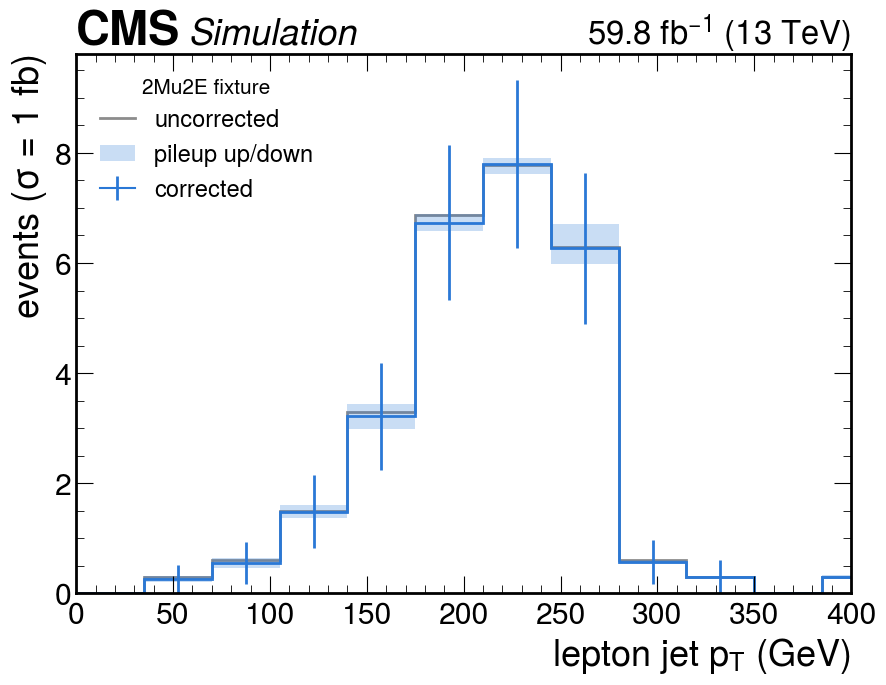

In [17]:
h = out["hists"]["lj_pt"][{"channel": "2mu2e"}]
print("syst categories:", list(h.axes["syst"]))

rebin = hist.rebin(5)
nominal = h[{"syst": "nominal"}][rebin]
fig, ax = plt.subplots(figsize=(10, 7))
hep.histplot(h[{"syst": "uncorrected"}][rebin], ax=ax, color=GRAY, lw=2, yerr=False, label="uncorrected", flow="none")
hep.histplot(nominal, ax=ax, color=BLUE, lw=2, label="corrected", flow="none")
study.band(ax, h[{"syst": "pileupUp"}][rebin], h[{"syst": "pileupDown"}][rebin], BLUE, label="pileup up/down")
ax.set_xlim(0, 400)
ax.set_xlabel(r"lepton jet $p_T$ (GeV)")
ax.set_ylabel(r"events ($\sigma$ = 1 fb)")
ax.legend(loc="upper left", fontsize=17, title="2Mu2E fixture", title_fontsize=15)
study.cms_label(ax, lumi=study.LUMI_2018)
study.save(fig, "tutorial_lj_pt_syst")
plt.show()

## 11. Closure: rebuilding the event weights

A check worth repeating whenever the corrections change: rebuild each selected
event's weight from its inputs with the `Corrections` API, independently of the
processor, and compare with the weight the processor used. The processor exports the
selected events through debug branches (fine for a check like this; plots are made from
histograms): the event number, the weight, and the lepton-jet constituents. The event
corrections are then read from the original NanoAOD branches of those events.

In [18]:
import awkward as ak

def lj(collection, *fields):
    # one entry per lepton-jet constituent of the selected events
    return {f"{collection}_{f}": (lambda s, e, f=f: ak.flatten(s["ljs"][collection][f], axis=2)) for f in fields}

DEBUG = {"event": lambda s, e: s["event_number"], "weight": lambda s, e: s["evt_weights"],
         **lj("pfMuons", "pt", "eta"), **lj("electrons", "pt", "eta", "deltaEtaSC")}
p = sidm_processor.SidmProcessor(["2mu2e"], ["lj_base"], corrections=True, debug=True,
                                 debug_branches=DEBUG, include_default_debug_branches=False)
with study.quiet():
    dbg = runner.run(fileset, treename="Events", processor_instance=p)["out"][SAMPLE]["debug"]["0.4"]["2mu2e"]
get = lambda name: dbg[name].value

# event corrections from the NanoAOD branches of the selected events
index = {int(e): i for i, e in enumerate(ak.to_numpy(events.event))}
rows = np.array([index[int(e)] for e in ak.to_numpy(get("event"))])
selected = events[rows]
pu_weight = pu.evaluate(ak.to_numpy(selected.Pileup.nTrueInt), "nominal")
prefire = ak.to_numpy(selected.L1PreFiringWeight.Nom)
gen = ak.to_numpy(selected.genWeight)

# object SFs from the exported constituents
muons = ak.zip({"pt": get("pfMuons_pt"), "eta": get("pfMuons_eta")})
electrons = ak.zip({"pt": get("electrons_pt"), "eta": get("electrons_eta"), "deltaEtaSC": get("electrons_deltaEtaSC")})
mu_sf = ak.to_numpy(ak.prod(corr.object_sf("muon_id", muons, "looseID"), axis=1))
el_sf = ak.to_numpy(ak.prod(corr.object_sf("electron_reco", electrons, "always"), axis=1))

rebuilt = gen * pu_weight * prefire * mu_sf * el_sf
processor_weight = ak.to_numpy(get("weight"))
print(f"{len(rebuilt)} selected events; largest relative difference: {np.max(np.abs(rebuilt / processor_weight - 1)):.1e}")

47 selected events; largest relative difference: 0.0e+00


Finally, `metadata.write_run_metadata(..., corrections=True)` records the same
provenance in the `.meta.yaml` sidecar written next to a saved output: for every
correction, the file it came from and the file's checksum.

In [19]:
prov = corr.provenance()
for name, info in prov["corrections"].items():
    print(f"{name:18s} {info['validity']:12s}", *[f"{f} (md5 {m[:8]})" for f, m in info["files"].items()] or ["NanoAOD branches"])

pileup             standard     LUM/Run2-2018-UL-NanoAODv9/2021-09-10/puWeights.json.gz (md5 7aa082dc)
l1_prefiring       standard     NanoAOD branches
muon_id            approximate  MUO/Run2-2018-UL-NanoAODv9/2024-07-02/muon_JPsi.json.gz (md5 f32163c3) MUO/Run2-2018-UL-NanoAODv9/2024-07-02/muon_Z.json.gz (md5 6dc5bb5d)
electron_reco      approximate  EGM/Run2-2018-UL-NanoAODv9/2024-07-02/electron.json.gz (md5 b46165ff)


## Summary

* A correction is a JSON tree evaluated by a fast C++ library. CMS publishes all of
  them on CVMFS under `/cvmfs/cms-griddata.cern.ch/cat/metadata/`, and we pin dated
  snapshots in `sidm/configs/corrections.yaml`.
* Inspect a file with `correction summary`; evaluate with numpy or awkward inputs;
  mind the `flow` of each binning and the POG-specific names of the variations.
* Our own measurements should be written as correctionlib files too (9a, 9b) and
  registered in the config (9c), so they are applied and varied like the POG ones.
* `SidmProcessor(corrections=True)` applies the default set to simulation and keeps
  every weight category in every cutflow row, and with `syst_hists=True` in every
  histogram. The weights close: rebuilt from their inputs, they equal the processor's.

Next: `01_standard_corrections.ipynb` applies all of this to the full signal and
background simulation, read from the merged outputs of the Condor campaign.